In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load retail sales dataset

df = pd.read_csv("retail_sales_dataset.csv")

# Display first 5 records
display(df.head())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (1000, 9)

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Statistical Summary:


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Records: 0


In [4]:
# Convert Date column into datetime format

df['Date'] = pd.to_datetime(df['Date'])

# Verify data type
print(df['Date'].dtype)

# Extract month, month name and quarter
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.month_name()
df['Quarter'] = df['Date'].dt.quarter

print("Date conversion completed!")
display(df.head())

datetime64[ns]
Date conversion completed!


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Month_Name,Quarter
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,11,November,4
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2,February,1
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,1,January,1
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,5,May,2
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,5,May,2


In [5]:
# Descriptive Statistics

numerical_columns = [
    'Age',
    'Quantity',
    'Price per Unit',
    'Total Amount'
]

print("========== DESCRIPTIVE STATISTICS ==========")

for col in numerical_columns:

    print(f"\nColumn: {col}")

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())

========== DESCRIPTIVE STATISTICS ==========

Column: Age
Mean: 41.392
Median: 42.0
Mode: 43
Standard Deviation: 13.681429659122527
Minimum: 18
Maximum: 64

Column: Quantity
Mean: 2.514
Median: 3.0
Mode: 4
Standard Deviation: 1.1327343409145356
Minimum: 1
Maximum: 4

Column: Price per Unit
Mean: 179.89
Median: 50.0
Mode: 50
Standard Deviation: 189.68135627129232
Minimum: 25
Maximum: 500

Column: Total Amount
Mean: 456.0
Median: 135.0
Mode: 50
Standard Deviation: 559.997631555123
Minimum: 25
Maximum: 2000


In [6]:
# Overall Business Statistics

total_sales = df['Total Amount'].sum()
total_transactions = df['Transaction ID'].nunique()
total_customers = df['Customer ID'].nunique()
average_sales = df['Total Amount'].mean()
total_quantity = df['Quantity'].sum()

print("========== BUSINESS SUMMARY ==========")

print("Total Revenue:", total_sales)
print("Total Transactions:", total_transactions)
print("Total Customers:", total_customers)
print("Average Transaction Value:", average_sales)
print("Total Quantity Sold:", total_quantity)

========== BUSINESS SUMMARY ==========
Total Revenue: 456000
Total Transactions: 1000
Total Customers: 1000
Average Transaction Value: 456.0
Total Quantity Sold: 2514


In [7]:
# Monthly Sales Analysis

monthly_sales = df.groupby('Month_Name')['Total Amount'].sum()

# Arrange months in calendar order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

print("Monthly Sales:")
display(monthly_sales)

Monthly Sales:


Month_Name
January      36980
February     44060
March        28990
April        33870
May          53150
June         36715
July         35465
August       36960
September    23620
October      46580
November     34920
December     44690
Name: Total Amount, dtype: int64

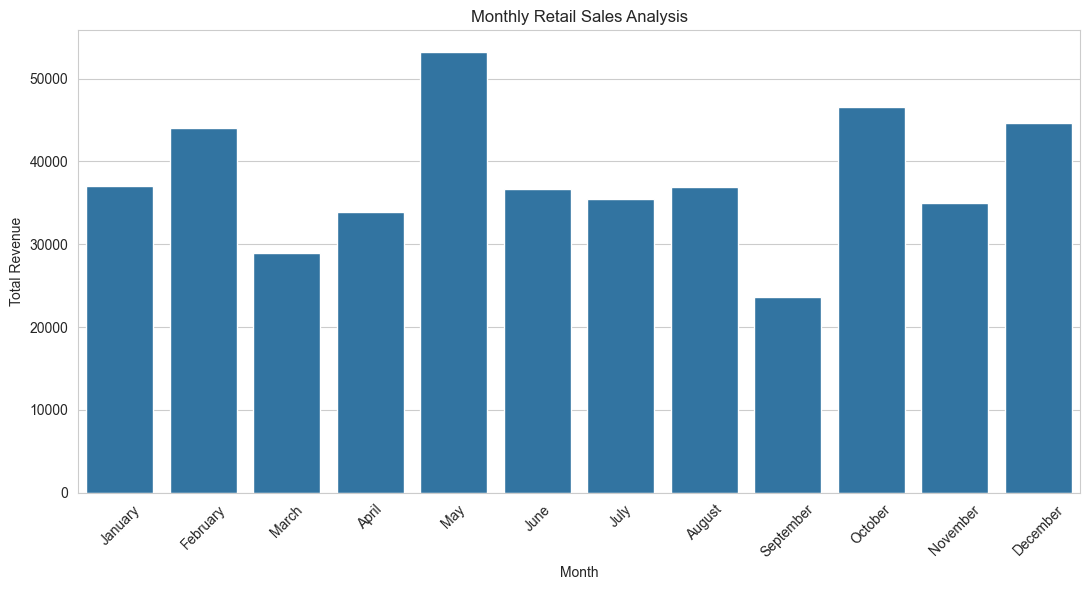

In [16]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales.values
)

plt.title('Monthly Retail Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Monthly Sales Analysis – Observations

1. May recorded the highest monthly revenue.
2. September recorded the lowest monthly revenue.
3. February, October, and December also showed relatively strong sales.
4. Sales revenue fluctuated throughout the year, indicating variations in monthly customer demand.

Business Insight:
The business should investigate the reasons behind lower sales in September and consider promotional campaigns during low-performing months.

In [18]:
# Quarterly Sales Analysis

quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

print("Quarterly Sales:")
display(quarterly_sales)

Quarterly Sales:


Quarter
1    110030
2    123735
3     96045
4    126190
Name: Total Amount, dtype: int64

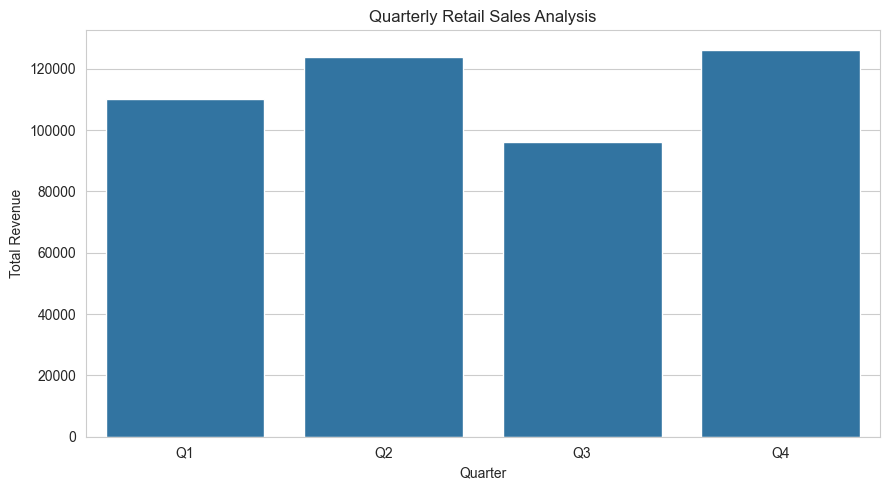

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=quarterly_sales.index,
    y=quarterly_sales.values
)

plt.title('Quarterly Retail Sales Analysis')
plt.xlabel('Quarter')
plt.ylabel('Total Revenue')

plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=['Q1', 'Q2', 'Q3', 'Q4']
)

plt.tight_layout()
plt.show()

### Quarterly Sales Analysis – Observations

1. Q4 recorded the highest quarterly revenue.
2. Q3 recorded the lowest quarterly revenue.
3. Q2 showed strong sales performance.
4. Revenue increased significantly from Q3 to Q4.

Business Insight:
The business should investigate the lower sales performance in Q3 and plan marketing campaigns before the final quarter to improve revenue.

Customer Gender Distribution:


Gender
Female    510
Male      490
Name: count, dtype: int64

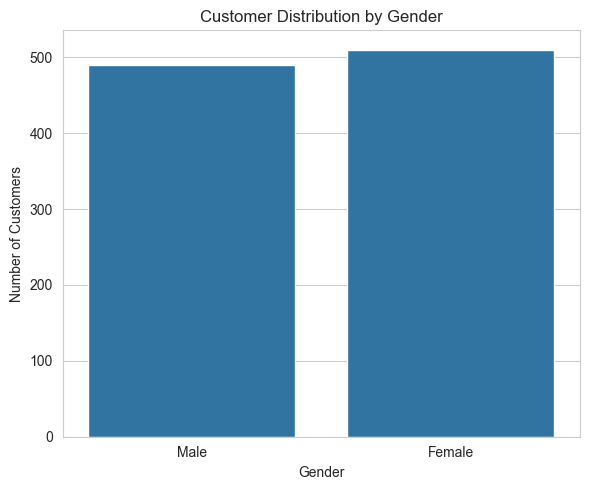

In [25]:
# Gender Distribution

gender_counts = df['Gender'].value_counts()

print("Customer Gender Distribution:")
display(gender_counts)

# Visualization
plt.figure(figsize=(6, 5))

sns.countplot(data=df, x='Gender')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [26]:
# Create age groups

bins = [0, 18, 25, 35, 45, 55, 100]

labels = [
    'Under 18',
    '18-25',
    '26-35',
    '36-45',
    '46-55',
    'Above 55'
]

df['Age_Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels
)

# Count customers in each age group
age_distribution = df['Age_Group'].value_counts().sort_index()

print("Customer Age Distribution:")
display(age_distribution)

Customer Age Distribution:


Age_Group
Under 18     21
18-25       148
26-35       205
36-45       202
46-55       229
Above 55    195
Name: count, dtype: int64

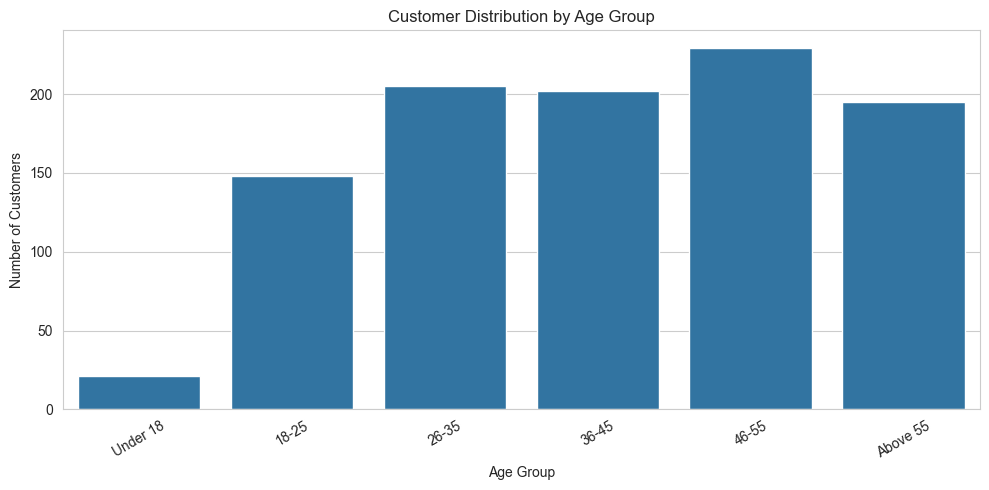

In [27]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='Age_Group'
)

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Customer Age Group Analysis – Observations

1. The 46–55 age group represents the largest customer segment.
2. Customers under 18 represent the smallest segment.
3. Customers aged 26–55 form a significant portion of the customer base.
4. The business serves customers from different age groups.

Business Insight:
The business can develop targeted marketing campaigns for the 26–55 age groups while exploring strategies to attract younger customers.

In [28]:
# Category-wise Revenue

category_sales = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)

print("Revenue by Product Category:")
display(category_sales)

Revenue by Product Category:


Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

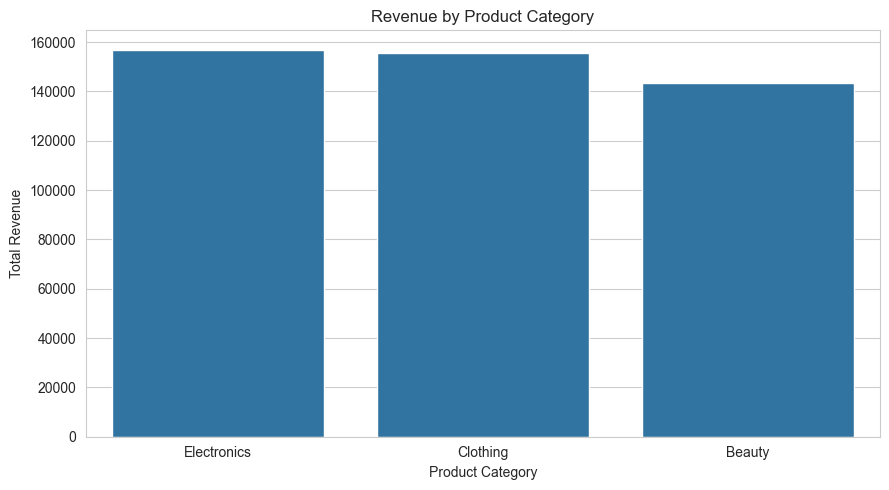

In [29]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

In [31]:
category_quantity = df.groupby('Product Category')['Quantity'].sum().sort_values(ascending=False)

print("Quantity Sold by Category:")
display(category_quantity)

Quantity Sold by Category:


Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

### Product Category Analysis – Observations

1. Clothing recorded the highest sales volume with 894 units.
2. Electronics recorded 849 units sold.
3. Beauty recorded the lowest sales volume with 771 units.
4. Clothing contributes approximately 35.56% of total quantity sold.

Business Insight:
The business should maintain sufficient inventory for Clothing products and investigate opportunities to increase Beauty category sales.

In [32]:
category_sales = df.groupby(
    'Product Category'
)['Total Amount'].sum().sort_values(ascending=False)

print("Revenue by Product Category:")
display(category_sales)

Revenue by Product Category:


Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

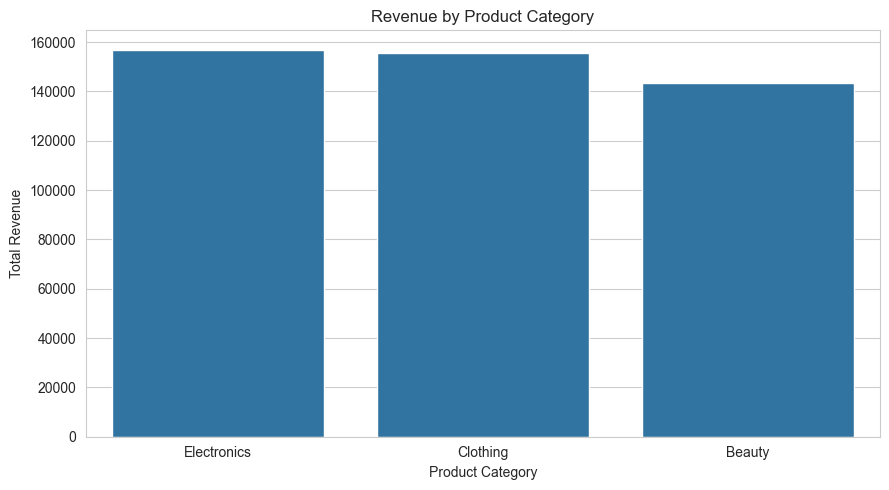

In [33]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

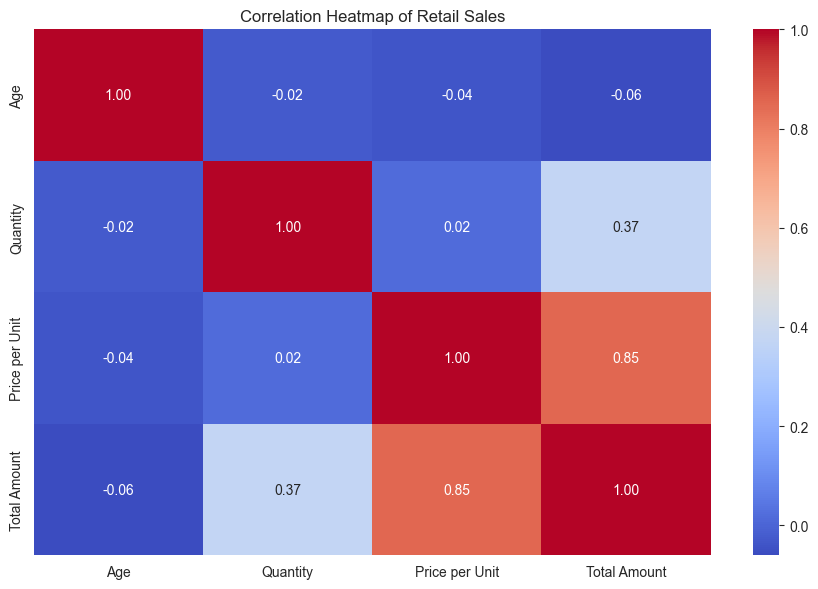

In [35]:
# Select numerical columns
numeric_df = df[
    ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
]

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Retail Sales')

plt.tight_layout()
plt.show()

### Correlation Heatmap – Observations

1. Price per Unit and Total Amount have a strong positive correlation of 0.85.
2. Quantity and Total Amount have a moderate positive correlation of 0.37.
3. Age and Total Amount show a very weak negative correlation of -0.06.
4. Age and Quantity have almost no correlation (-0.02).

Business Insight:
Product pricing and purchase quantity are more closely associated with transaction revenue than customer age.

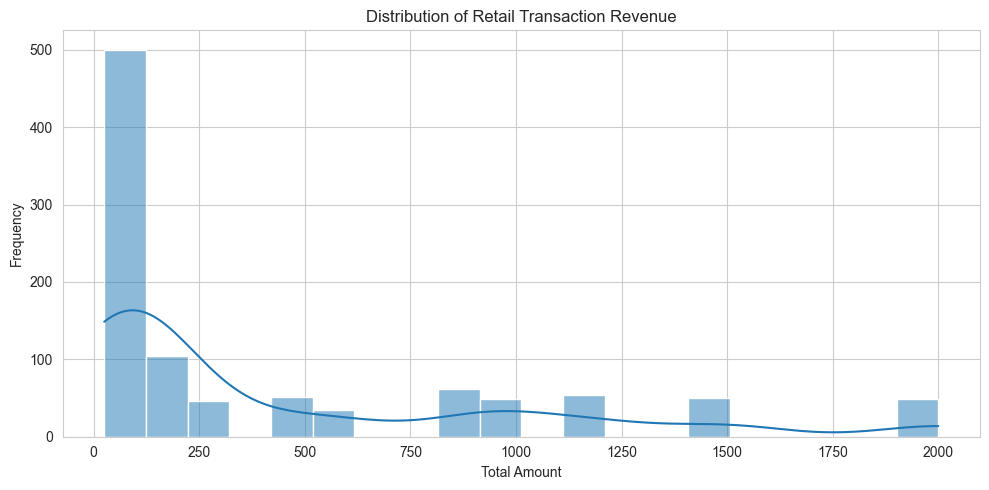

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Total Amount',
    bins=20,
    kde=True
)

plt.title('Distribution of Retail Transaction Revenue')
plt.xlabel('Total Amount')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### Revenue Distribution Analysis – Observations

1. Most transactions have relatively low transaction values.
2. The distribution is positively skewed (right-skewed).
3. A smaller number of transactions have higher transaction values.
4. Some transactions reach approximately ₹2,000.

Business Insight:
The business can investigate high-value transactions to understand premium purchasing behaviour and identify opportunities to increase average transaction value.

## Business Recommendations

1. Inventory Management:
   Clothing recorded the highest sales quantity (894 units).
   Maintain sufficient stock to meet customer demand.

2. Seasonal Marketing:
   September recorded the lowest monthly revenue.
   Introduce targeted promotional campaigns during low-performing months.

3. Customer Targeting:
   Customers aged 26–55 represent a significant customer segment.
   Develop targeted marketing campaigns to retain these customers and attract younger buyers.